# 《到期日》实验可视化

新线开通后，受益区租客通勤少 **9.7 分钟**，但他们只占全部租客的 8.0%。这些区域本来就住满了，几乎没人能迁入；统计窗口内，受益区租金只比没有新线时多涨 **1.32 个指数点**。

规则版，没有 LLM，四组各 100 局，同一编号的随机种子配对。这些数字用来检查设计，不代表北京的真实情况。

**怎么用：** 图已经保存在文件里，打开就能看。数据也在文件里，从上到下运行不需要其他文件，只需要 matplotlib、numpy 和 pandas，Colab 自带。

In [1]:
#@title 准备：载入工具和中文字体
import base64, gzip, json, os, subprocess, sys, uuid

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import HTML, display
from matplotlib import font_manager, patheffects
from matplotlib.colors import LinearSegmentedColormap

CJK = ["PingFang SC", "Hiragino Sans GB", "Heiti TC", "STHeiti", "Arial Unicode MS", "Microsoft YaHei", "SimHei", "Noto Sans CJK SC", "Noto Sans CJK JP", "WenQuanYi Micro Hei"]
installed = {f.name for f in font_manager.fontManager.ttflist}
if "google.colab" in sys.modules and not installed & set(CJK):
    subprocess.run(["apt-get", "-qq", "install", "-y", "fonts-noto-cjk"], capture_output=True)
    path = "/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc"
    if os.path.exists(path):
        font_manager.fontManager.addfont(path)
        installed = {f.name for f in font_manager.fontManager.ttflist}
found = [f for f in CJK if f in installed]
if not found:
    print("没有找到中文字体，图里的中文会显示成方块。安装任意一种中文字体后重新运行。")
plt.rcParams.update({"font.family": "sans-serif", "font.sans-serif": found + ["DejaVu Sans"], "axes.unicode_minus": False, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#9a9ea4", "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.labelsize": 9, "xtick.labelsize": 9, "ytick.labelsize": 9,
                     "xtick.color": "#6b6f76", "ytick.color": "#6b6f76", "figure.dpi": 110, "savefig.dpi": 110})
ORANGE, GREY, BLUE, INK, MUTED = "#d95926", "#6b6f76", "#2a78d6", "#1b1f24", "#b4b8bd"

In [2]:
#@title 数据（已放在文件里，不用下载）
DATA_PACKED = """
...
DeRTJhkorTf8/NvPv/0fWT8MUWRuGgA=
"""
DATA = json.loads(gzip.decompress(base64.b64decode(DATA_PACKED)))

In [3]:
#@title 画图用的小工具
monthly = pd.DataFrame(DATA["monthly"])
by_month = pd.DataFrame(DATA["effect_by_month"])
effects = pd.DataFrame(DATA["effects"])
zones = pd.DataFrame(DATA["zones"])
ledger = pd.DataFrame(DATA["ledger"])
assumptions = pd.DataFrame(DATA["assumptions"])
rules = pd.DataFrame(DATA["landlord_rules"])
real_vs_rule = pd.DataFrame(DATA["real_vs_rule"])
baseline = pd.DataFrame(DATA["baseline"])
LEVEL = {row["key"]: row["value"] for row in DATA["levels"]}
OPENS, MONTHS, TAIL = LEVEL["opens"], LEVEL["months"], LEVEL["tail"]

# 两个因素，两种画法：有新线用橙色，没有新线用灰色；租金冻结用虚线，租金变化用实线
ARMS = {"A": dict(color=GREY, ls="-", label="A 没有新线，租金变化"), "A0": dict(color=GREY, ls="--", label="A0 没有新线，租金冻结"),
        "C": dict(color=ORANGE, ls="-", label="C 新线，租金变化"), "B": dict(color=ORANGE, ls="--", label="B 新线，租金冻结")}

def mark_time(ax):
    # 竖线是开通，阴影是统计窗口
    ax.axvline(OPENS - 0.5, color="#9a9ea4", lw=1)
    ax.axvspan(MONTHS - TAIL, MONTHS, color="#eceef0", lw=0, zorder=0)
    ax.set_xlim(0, MONTHS)
    ax.set_xticks([12, 24, 36, 48, 60])
    ax.grid(axis="y", color="#eceef0", lw=1)
    ax.set_axisbelow(True)

def whisker(ax, x, lo, hi, y, color, size=5, lw=1.6, **kw):
    ax.plot([lo, hi], [y, y], color=color, lw=lw, solid_capstyle="round", zorder=3, **kw)
    ax.plot([x], [y], "o", color=color, ms=size, zorder=4)

def sign(v, d=1):
    return "0" if abs(v) < 0.5 * 10 ** -d else f"{v:+,.{d}f}"

## 实验设计：两个因素，四组

所有租客都在 CBD 上班，1,200 间房分布在 24 个住房区域。每回合一个月，共 60 个月。第 25 个月，假想的东向快线开通，果园和武夷花园的地铁通勤变短；冻结组的租金从这个月起不再变化。结果取最后 12 个月的平均。

| | 租金正常变化 | 租金冻结 |
|---|---|---|
| **没有新线** | A：基线 | A0：对照，用来扣除冻结本身 |
| **有新线** | C：新线，租金变化 | B：新线，租金不变 |

- **直接效应 = B − A0：** 租金不动时，新线带来多少
- **总效应 = C − A：** 租金能动时，新线带来多少
- **交互影响 = 总效应 − 直接效应：** 租金反应把结果改变了多少

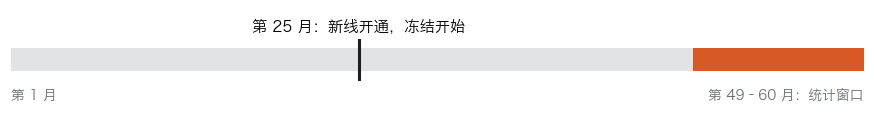

In [4]:
fig, ax = plt.subplots(figsize=(10, 1.15))
ax.barh(0, MONTHS, height=0.35, color="#e1e3e6")
ax.barh(0, TAIL, left=MONTHS - TAIL, height=0.35, color=ORANGE)
ax.plot([OPENS - 0.5] * 2, [-0.3, 0.3], color=INK, lw=2)
ax.text(OPENS - 0.5, 0.42, f"第 {OPENS} 月：新线开通，冻结开始", ha="center", fontsize=10)
ax.text(0, -0.62, "第 1 月", fontsize=9, color=GREY)
ax.text(MONTHS, -0.62, f"第 {MONTHS - TAIL + 1}–{MONTHS} 月：统计窗口", ha="right", fontsize=9, color=GREY)
ax.set_xlim(0, MONTHS); ax.set_ylim(-0.75, 0.75); ax.axis("off")
plt.show()

## 回放一局：每个点是一间房

实心点是有人住的房间，空心点是空房。这是编号 0 的一局，不是平均值；四组用同一个种子，所以开通前完全相同，之后才分开。

按“播放”看租客怎样搬家，切换分组时月份不变。在 notebook 里，如果下面没有出现地图，从上到下运行一次（Run All）。

地铁线是 2018 年路网（OpenStreetMap）。区域按真实方向摆放，为了放下所有点，靠近中心的区域向外移开，最多约 5.3 公里。东向快线只是示意，没有真实走向。

In [5]:
#@title 回放的网页代码
REPLAY_PAGE = r'''
<style>
#__UID__ { all: initial; display: block; font-family: "PingFang SC", "Hiragino Sans GB", "Microsoft YaHei", "Noto Sans CJK SC", system-ui, sans-serif; font-size: 13px; line-height: 1.5; color: #1b1f24; background: #ffffff; padding: 12px; border: 1px solid #dfe2e6; border-radius: 6px; }
#__UID__ * { box-sizing: border-box; font-family: inherit; }
#__UID__ .row { display: flex; flex-wrap: wrap; gap: 8px 18px; align-items: center; margin-bottom: 10px; }
#__UID__ .group { display: flex; flex-wrap: wrap; gap: 4px; align-items: center; }
#__UID__ .name { color: #6b6f76; font-size: 12px; margin-right: 4px; }
#__UID__ button { font-size: 12px; color: #1b1f24; background: #ffffff; border: 1px solid #c9cdd2; border-radius: 4px; padding: 4px 9px; cursor: pointer; }
#__UID__ button[aria-pressed="true"] { background: #1b1f24; color: #ffffff; border-color: #1b1f24; }
#__UID__ .slider { flex: 1 1 200px; display: flex; gap: 8px; align-items: center; min-width: 200px; }
#__UID__ input[type=range] { flex: 1; accent-color: #1b1f24; }
#__UID__ .stage { display: flex; flex-wrap: wrap; gap: 16px; align-items: flex-start; }
#__UID__ .map { flex: 3 1 420px; min-width: 0; position: relative; }
#__UID__ canvas { display: block; width: 100%; }
#__UID__ .side { flex: 1 1 260px; min-width: 0; }
#__UID__ .month { font-size: 22px; margin-bottom: 2px; }
#__UID__ .chips { color: #6b6f76; font-size: 12px; margin-bottom: 10px; }
#__UID__ .stats { display: grid; grid-template-columns: minmax(0, 1fr) auto; gap: 2px 14px; margin: 0 0 12px; font-size: 12px; }
#__UID__ .k { color: #6b6f76; }
#__UID__ .v { text-align: right; font-variant-numeric: tabular-nums; }
#__UID__ h4 { font-size: 13px; font-weight: 600; margin: 0 0 4px; }
#__UID__ ul { list-style: none; margin: 0; padding: 0; font-size: 12px; }
#__UID__ li { border-top: 1px solid #e6e8eb; padding: 4px 0; }
#__UID__ .legend { display: flex; flex-wrap: wrap; gap: 4px 14px; color: #6b6f76; font-size: 12px; margin-top: 8px; align-items: center; }
#__UID__ .legend span { display: inline-flex; gap: 5px; align-items: center; }
#__UID__ .dot { width: 9px; height: 9px; border-radius: 50%; display: inline-block; }
#__UID__ .ramp { width: 72px; height: 9px; border-radius: 2px; display: inline-block; }
#__UID__ .tip { position: absolute; pointer-events: none; opacity: 0; background: #ffffff; border: 1px solid #c9cdd2; border-radius: 4px; padding: 4px 8px; font-size: 12px; white-space: nowrap; box-shadow: 0 2px 8px rgba(0,0,0,.12); }
</style>
<div id="__UID__">
  <p class="fallback">如果这里没有出现地图，请从上到下运行一次 notebook。</p>
  <div class="ready" hidden>
    <div class="row">
      <div class="group"><span class="name">实验组</span>
        <button data-arm="A" aria-pressed="false">A 没有新线</button><button data-arm="A0" aria-pressed="false">A0 冻结</button><button data-arm="B" aria-pressed="false">B 新线，冻结</button><button data-arm="C" aria-pressed="true">C 新线，变化</button>
      </div>
      <div class="group"><span class="name">颜色</span>
        <button data-mode="commute" aria-pressed="true">通勤时间</button><button data-mode="rent" aria-pressed="false">房租变化</button><button data-mode="income" aria-pressed="false">收入组</button><button data-mode="way" aria-pressed="false">上班方式</button>
      </div>
      <div class="slider"><button class="play">播放</button><input class="range" type="range" min="0" max="60" step="1" value="25" aria-label="月份"></div>
    </div>
    <div class="stage">
      <div class="map"><canvas role="img" aria-label="北京地图上的房间点阵回放，每个点是一间房"></canvas><div class="tip"></div><div class="legend"></div></div>
      <div class="side">
        <div class="month">第 <span class="m"></span> 个月</div>
        <div class="chips"></div>
        <div class="stats">
          <span class="k">受益区平均通勤（分钟）</span><span class="v" data-stat="commute_in"></span>
          <span class="k">其他区域平均通勤（分钟）</span><span class="v" data-stat="commute_out"></span>
          <span class="k">受益区房租，起始价 = 100</span><span class="v" data-stat="rent_in"></span>
          <span class="k">其他区域房租，起始价 = 100</span><span class="v" data-stat="rent_out"></span>
          <span class="k">受益区空房</span><span class="v" data-stat="vacant_in"></span>
          <span class="k">其他区域空房</span><span class="v" data-stat="vacant_out"></span>
          <span class="k">本月到期</span><span class="v" data-stat="renewals"></span>
          <span class="k">本月搬家</span><span class="v" data-stat="moves"></span>
          <span class="k">本月离开（付不起）</span><span class="v" data-stat="left"></span>
          <span class="k">本月新来者进不来</span><span class="v" data-stat="blocked"></span>
        </div>
        <h4>这个月发生了什么</h4>
        <ul class="feed"></ul>
      </div>
    </div>
  </div>
</div>
<script>
(function () {
  const root = document.getElementById('__UID__');
  if (!root) return;
  const D = __DATA__;
  const $ = (s) => root.querySelector(s);
  const $$ = (s) => [...root.querySelectorAll(s)];
  $('.fallback').hidden = true;
  $('.ready').hidden = false;
  const MODE_NAMES = ['地铁', '骑车接地铁', '公交', '公交换乘', '电动车', '自行车', '步行', '私家车', '打车'];
  const MODE_CLASS = ['subway', 'subway', 'bus', 'bus', 'bike', 'bike', 'bike', 'car', 'car'];
  const GROUPS = ['较低收入', '中等收入', '较高收入'];
  const GROUP_COLOURS = ['#2a78d6', '#d95926', '#1baf7a'];
  const WAY_COLOURS = {subway: '#2a78d6', bus: '#1baf7a', bike: '#d95926', car: '#9a9ea4'};
  const INK = '#1b1f24', MUTED = '#6b6f76', LINE = '#c9cdd2', DISC = '#f5f6f7', ORANGE = '#d95926', BAD = '#d03b3b';
  const COMMUTE = [20, 110], RENT = 0.1, STEP = 850;
  const hex = (h) => [1, 3, 5].map((i) => parseInt(h.slice(i, i + 2), 16));
  const mix = (a, b, t) => { const x = hex(a), y = hex(b); return `rgb(${x.map((v, i) => Math.round(v + (y[i] - v) * t)).join(',')})`; };
  const n = (v) => Number(v).toLocaleString('en-US');
  const zoneOf = new Map(D.zones.map((z) => [z.id, z]));
  const rooms = D.rooms.map((r) => ({zone: zoneOf.get(r.zone), start: r.start, x: r.x, y: r.y}));
  const S = {arm: 'C', frame: 25, mode: 'commute', playing: false, frames: {}, anim: null, raf: 0, hover: null, W: 0, H: 0};
  const canvas = $('canvas'), ctx = canvas.getContext('2d'), tip = $('.tip');
  const base = document.createElement('canvas');
  const dpr = Math.min(window.devicePixelRatio || 1, 2);

  function framesOf(arm) {
    if (S.frames[arm]) return S.frames[arm];
    const count = rooms.length;
    const who = new Int16Array(count).fill(-1), rent = new Int32Array(count), mode = new Int8Array(count).fill(-1), mins = new Int16Array(count);
    S.frames[arm] = D.arms[arm].rows.map((row) => {
      row.rooms.forEach(([i, t, money, way, minutes]) => { who[i] = t; rent[i] = money; mode[i] = way; mins[i] = minutes; });
      return {who: who.slice(), rent: rent.slice(), mode: mode.slice(), mins: mins.slice(), events: row.events, renew: row.renew};
    });
    return S.frames[arm];
  }

  function colourOf(f, i) {
    if (f.who[i] < 0) return MUTED;
    if (S.mode === 'commute') return mix('#b7d3f6', '#0d366b', Math.max(0, Math.min(1, (f.mins[i] - COMMUTE[0]) / (COMMUTE[1] - COMMUTE[0]))));
    if (S.mode === 'rent') {
      const change = f.rent[i] / rooms[i].start - 1;
      const t = Math.min(1, Math.abs(change) / RENT);
      return mix('#d9d8d2', change < 0 ? '#2a78d6' : '#e34948', t);
    }
    if (S.mode === 'income') { const p = D.arms[S.arm].people[f.who[i]]; return GROUP_COLOURS[p ? p[0] : 0]; }
    return WAY_COLOURS[MODE_CLASS[f.mode[i]]];
  }

  function drawBase() {
    const k = S.W / D.width, c = base.getContext('2d');
    c.setTransform(dpr, 0, 0, dpr, 0, 0);
    c.clearRect(0, 0, S.W, S.H);
    c.strokeStyle = LINE; c.lineWidth = 1; c.lineJoin = 'round';
    D.metro.forEach((pts) => { c.beginPath(); pts.forEach(([x, y], i) => (i ? c.lineTo(x * k, y * k) : c.moveTo(x * k, y * k))); c.stroke(); });
    D.zones.forEach((z) => {
      c.beginPath(); c.arc(z.x * k, z.y * k, z.r * k, 0, Math.PI * 2);
      c.fillStyle = DISC; c.fill();
      c.lineWidth = z.treated ? 2 : 1; c.strokeStyle = z.treated ? ORANGE : '#e1e3e6'; c.stroke();
    });
    c.textAlign = 'center'; c.textBaseline = 'middle';
    const family = getComputedStyle(root).fontFamily;
    D.zones.forEach((z) => {
      if (S.W < 560 && !z.major) return;
      c.font = `${z.treated ? '600 ' : ''}12px ${family}`;
      c.fillStyle = z.treated ? INK : MUTED;
      c.fillText(z.name, z.lx * k, z.ly * k);
    });
  }

  function paint(t) {
    const k = S.W / D.width, f = framesOf(S.arm)[S.frame], anim = S.anim, r = Math.max(1.3, 3.5 * k);
    ctx.setTransform(dpr, 0, 0, dpr, 0, 0);
    ctx.clearRect(0, 0, S.W, S.H);
    ctx.drawImage(base, 0, 0, S.W, S.H);
    if ((S.arm === 'B' || S.arm === 'C') && S.frame >= D.opens) {
      const a = zoneOf.get('Z05'), b = zoneOf.get('Z11');
      ctx.save(); ctx.setLineDash([7, 5]); ctx.lineWidth = 2; ctx.strokeStyle = ORANGE;
      ctx.beginPath(); ctx.moveTo(D.cbd[0] * k, D.cbd[1] * k); ctx.lineTo(a.x * k, a.y * k); ctx.lineTo(b.x * k, b.y * k); ctx.stroke(); ctx.restore();
    }
    const waiting = anim && t < 0.9 ? anim.landing : null;
    rooms.forEach((room, i) => {
      ctx.beginPath(); ctx.arc(room.x * k, room.y * k, r, 0, Math.PI * 2);
      if (f.who[i] < 0 || (waiting && waiting.has(i))) { ctx.lineWidth = 1; ctx.strokeStyle = MUTED; ctx.stroke(); }
      else { ctx.fillStyle = colourOf(f, i); ctx.fill(); }
    });
    if (anim) anim.movers.forEach((m) => {
      const e = t < 0.5 ? 2 * t * t : 1 - 2 * (1 - t) * (1 - t);
      ctx.globalAlpha = m.fade === 'out' ? 1 - t : m.fade === 'in' ? Math.min(1, t * 2.5) : 1;
      ctx.beginPath();
      ctx.arc((m.x0 + (m.x1 - m.x0) * e) * k, (m.y0 + (m.y1 - m.y0) * e - Math.sin(e * Math.PI) * m.lift) * k, r + 0.8, 0, Math.PI * 2);
      ctx.fillStyle = m.colour; ctx.fill(); ctx.globalAlpha = 1;
    });
    const cx = D.cbd[0] * k, cy = D.cbd[1] * k, s = Math.max(4, 7 * k);
    ctx.beginPath(); ctx.moveTo(cx, cy - s); ctx.lineTo(cx + s, cy); ctx.lineTo(cx, cy + s); ctx.lineTo(cx - s, cy); ctx.closePath();
    ctx.fillStyle = INK; ctx.fill();
    if (S.W >= 560) { ctx.font = `600 11px ${getComputedStyle(root).fontFamily}`; ctx.textAlign = 'center'; ctx.textBaseline = 'middle'; ctx.fillText('CBD', cx, cy + s + 9); }
  }

  function makeAnim(from, to) {
    const frames = framesOf(S.arm), before = frames[from], after = frames[to], movers = [], landing = new Set();
    if (!window.matchMedia('(prefers-reduced-motion: reduce)').matches) {
      const outward = (room, d) => {
        const dx = room.x - D.cbd[0], dy = room.y - D.cbd[1], len = Math.hypot(dx, dy) || 1;
        return [room.x + (dx / len) * d, room.y + (dy / len) * d];
      };
      after.events.forEach((e) => {
        if (e[0] === 'move') {
          const a = rooms[e[2]], b = rooms[e[3]];
          movers.push({x0: a.x, y0: a.y, x1: b.x, y1: b.y, lift: Math.min(60, Math.hypot(b.x - a.x, b.y - a.y) * 0.2), colour: colourOf(after, e[3])});
          landing.add(e[3]);
        } else if (e[0] === 'arrive') {
          const room = rooms[e[2]], [x0, y0] = outward(room, 70);
          movers.push({x0, y0, x1: room.x, y1: room.y, lift: 0, fade: 'in', colour: colourOf(after, e[2])});
          landing.add(e[2]);
        } else if (e[0] === 'exits' || e[0] === 'left') {
          const room = rooms[e[2]], [x1, y1] = outward(room, e[0] === 'left' ? 110 : 70);
          movers.push({x0: room.x, y0: room.y, x1, y1, lift: 0, fade: 'out', colour: e[0] === 'left' ? BAD : colourOf(before, e[2])});
        }
      });
    }
    return {movers, landing, start: performance.now(), dur: STEP};
  }

  function tick(now) {
    S.raf = 0;
    if (S.anim) {
      const t = Math.min(1, Math.max(0, (now - S.anim.start) / S.anim.dur));
      paint(t);
      if (t >= 1) {
        S.anim = null;
        if (S.playing) { if (S.frame < D.last) step(); else setPlaying(false); }
      }
    }
    if (S.anim && !S.raf) S.raf = requestAnimationFrame(tick);
  }

  function step() {
    const from = S.frame;
    S.frame = from + 1;
    S.anim = makeAnim(from, S.frame);
    refresh();
    if (!S.raf) S.raf = requestAnimationFrame(tick);
  }

  function setPlaying(on) {
    S.playing = on;
    if (on) {
      if (S.frame >= D.last) S.frame = 0;
      if (!S.anim) step();
    }
    refresh();
  }

  function stats() {
    const f = framesOf(S.arm)[S.frame];
    const part = (wanted) => {
      let count = 0, vacant = 0, mins = 0, rent = 0;
      rooms.forEach((room, i) => {
        if (room.zone.treated !== wanted) return;
        count += 1; rent += f.rent[i] / room.start;
        if (f.who[i] < 0) vacant += 1; else mins += f.mins[i];
      });
      return {count, vacant, mins: mins / Math.max(1, count - vacant), rent: (100 * rent) / Math.max(1, count)};
    };
    const a = part(true), b = part(false), tally = {move: 0, left: 0, blocked: 0};
    f.events.forEach((e) => { if (e[0] in tally) tally[e[0]] += 1; });
    return {commute_in: a.mins.toFixed(1), commute_out: b.mins.toFixed(1), rent_in: a.rent.toFixed(1), rent_out: b.rent.toFixed(1), vacant_in: `${a.vacant} / ${a.count}`, vacant_out: `${b.vacant} / ${b.count}`,
      renewals: S.frame ? f.renew[0] : '—', moves: S.frame ? tally.move : '—', left: S.frame ? tally.left : '—', blocked: S.frame ? tally.blocked : '—'};
  }

  function eventText(e) {
    const people = D.arms[S.arm].people;
    const who = (v) => { const p = people[v]; return p ? `${GROUPS[p[0]]}，月入 ${n(p[1])}` : ''; };
    if (e[0] === 'move') {
      const from = rooms[e[2]].zone.name, to = rooms[e[3]].zone.name;
      return `${who(e[1])}：续租报价 ${n(e[5])}（现租 ${n(e[4])}），${from === to ? `在${from}换了一间` : `从${from}搬到${to}`}，房租 ${n(e[6])}，${MODE_NAMES[e[9]]} ${e[10]} 分钟`;
    }
    if (e[0] === 'left') return `${who(e[1])}：续租报价 ${n(e[4])}（现租 ${n(e[3])}），找不到负担得起的房间，离开${rooms[e[2]].zone.name}`;
    if (e[0] === 'blocked') return `新来者（${GROUPS[e[1]]}，月入 ${n(e[2])}）看房 3 次，没有负担得起的房间`;
    if (e[0] === 'arrive') return `新租客（${who(e[1])}）住进${rooms[e[2]].zone.name}，房租 ${n(e[3])}，${MODE_NAMES[e[4]]} ${e[5]} 分钟`;
    return '';
  }

  function feed() {
    if (!S.frame) return ['起始状态：所有租客入住，房东还没有调价。'];
    const ev = framesOf(S.arm)[S.frame].events;
    const touches = (e) => e[0] === 'move' && (rooms[e[2]].zone.treated || rooms[e[3]].zone.treated);
    const pick = [...ev.filter((e) => e[0] === 'left'), ...ev.filter(touches), ...ev.filter((e) => e[0] === 'move' && !touches(e)).slice(0, 3), ...ev.filter((e) => e[0] === 'blocked').slice(0, 1),
      ...ev.filter((e) => e[0] === 'arrive' && rooms[e[2]].zone.treated).slice(0, 1), ...ev.filter((e) => e[0] === 'arrive').slice(0, 1)];
    return [...new Set(pick)].slice(0, 6).map(eventText);
  }

  function legend() {
    const box = $('.legend');
    box.replaceChildren();
    const add = (style, cls, text) => {
      const item = document.createElement('span');
      const mark = document.createElement('i');
      mark.className = cls;
      Object.assign(mark.style, style);
      item.append(mark, document.createTextNode(text));
      box.append(item);
    };
    if (S.mode === 'commute') add({background: 'linear-gradient(90deg,#b7d3f6,#0d366b)'}, 'ramp', `单程通勤 ${COMMUTE[0]} 到 ${COMMUTE[1]} 分钟及以上`);
    if (S.mode === 'rent') add({background: 'linear-gradient(90deg,#2a78d6,#d9d8d2,#e34948)'}, 'ramp', `房租比起始价低 ${RENT * 100}% 到高 ${RENT * 100}%`);
    if (S.mode === 'income') GROUPS.forEach((g, i) => add({background: GROUP_COLOURS[i]}, 'dot', g));
    if (S.mode === 'way') [['subway', '地铁（含骑车接地铁）'], ['bus', '公交'], ['bike', '电动车、自行车、步行'], ['car', '私家车、打车']].forEach(([k, t]) => add({background: WAY_COLOURS[k]}, 'dot', t));
    add({border: `1px solid ${MUTED}`}, 'dot', '空房');
    add({border: `2px solid ${ORANGE}`}, 'dot', '受益区');
    if (S.arm === 'B' || S.arm === 'C') add({height: '0', width: '26px', borderTop: `2px dashed ${ORANGE}`, borderRadius: '0'}, 'ramp', '假想东向快线（开通后）');
  }

  function showZone(z) {
    const f = framesOf(S.arm)[S.frame];
    let lived = 0, rent = 0, mins = 0;
    rooms.forEach((room, i) => {
      if (room.zone !== z || f.who[i] < 0) return;
      lived += 1; rent += f.rent[i]; mins += f.mins[i];
    });
    tip.textContent = `${z.name}${z.treated ? '（受益区）' : ''}：有人住 ${lived} / ${z.rooms} 间，平均房租 ${n(Math.round(rent / Math.max(1, lived)))} 元，平均通勤 ${(mins / Math.max(1, lived)).toFixed(1)} 分钟`;
    tip.style.opacity = 1;
    const k = S.W / D.width;
    tip.style.left = `${Math.max(0, Math.min(S.W - tip.offsetWidth, z.x * k - tip.offsetWidth / 2))}px`;
    tip.style.top = `${Math.max(0, (z.y - z.r) * k - tip.offsetHeight - 4)}px`;
  }

  function refresh() {
    $$('[data-arm]').forEach((b) => b.setAttribute('aria-pressed', String(b.dataset.arm === S.arm)));
    $$('[data-mode]').forEach((b) => b.setAttribute('aria-pressed', String(b.dataset.mode === S.mode)));
    $('.play').textContent = S.playing ? '暂停' : '播放';
    $('.range').value = String(S.frame);
    $('.m').textContent = S.frame;
    const hasLine = S.arm === 'B' || S.arm === 'C', opened = S.frame >= D.opens;
    const tags = [hasLine ? (opened ? '新线已开通' : '新线未开通') : '本组没有新线'];
    if ((S.arm === 'A0' || S.arm === 'B') && opened) tags.push('租金已冻结');
    $('.chips').textContent = tags.join(' · ');
    const v = stats();
    $$('[data-stat]').forEach((el) => { el.textContent = v[el.dataset.stat]; });
    $('.feed').replaceChildren(...feed().map((t) => { const li = document.createElement('li'); li.textContent = t; return li; }));
    legend();
    if (S.hover) showZone(S.hover);
  }

  function fit() {
    const W = Math.round($('.map').clientWidth || 600), H = Math.round((W * D.height) / D.width);
    if (W === S.W && H === S.H) return;
    S.W = W; S.H = H;
    canvas.width = W * dpr; canvas.height = H * dpr; canvas.style.height = `${H}px`;
    base.width = W * dpr; base.height = H * dpr;
    drawBase();
    if (!S.anim) paint(1);
  }

  $$('[data-arm]').forEach((b) => b.addEventListener('click', () => {
    S.arm = b.dataset.arm; S.anim = null; refresh(); paint(1);
    if (S.playing) step();
  }));
  $$('[data-mode]').forEach((b) => b.addEventListener('click', () => { S.mode = b.dataset.mode; refresh(); if (!S.anim) paint(1); }));
  $('.play').addEventListener('click', () => setPlaying(!S.playing));
  $('.range').addEventListener('input', (e) => { S.frame = Number(e.target.value); S.anim = null; S.playing = false; refresh(); paint(1); });
  canvas.addEventListener('pointermove', (event) => {
    const rect = canvas.getBoundingClientRect(), k = S.W / D.width;
    const x = (event.clientX - rect.left) / k, y = (event.clientY - rect.top) / k;
    S.hover = D.zones.find((z) => Math.hypot(z.x - x, z.y - y) <= z.r) || null;
    if (S.hover) showZone(S.hover); else tip.style.opacity = 0;
  });
  canvas.addEventListener('pointerleave', () => { S.hover = null; tip.style.opacity = 0; });
  if (window.ResizeObserver) new ResizeObserver(fit).observe($('.map'));
  fit();
  refresh();
  paint(1);
})();
</script>

'''

In [6]:
def show_replay():
    rows_by_arm = {arm: [] for arm in ARMS}
    for row in sorted(DATA["replay"], key=lambda r: r["month"]):
        rows_by_arm[row["arm"]].append({"rooms": row["rooms"], "events": row["events"], "renew": row["renew"]})
    people = {row["arm"]: row["people"] for row in DATA["replay_people"]}
    size = DATA["map"][0]
    payload = {
        "width": size["width"], "height": size["height"], "cbd": [size["cbd_x"], size["cbd_y"]], "opens": OPENS, "last": MONTHS, "metro": [line["points"] for line in DATA["metro"]],
        "zones": [{"id": z["zone"], "name": z["name"], "x": z["x"], "y": z["y"], "r": z["r"], "lx": z["lx"], "ly": z["ly"], "major": z["major"], "treated": z["treated"], "rooms": z["rooms"]} for z in DATA["zones"]],
        "rooms": [{"zone": r["zone"], "start": r["start"], "x": r["x"], "y": r["y"]} for r in DATA["replay_rooms"]],
        "arms": {arm: {"rows": rows_by_arm[arm], "people": people[arm]} for arm in ARMS},
    }
    uid = "ld" + uuid.uuid4().hex[:10]
    display(HTML(REPLAY_PAGE.replace("__UID__", uid).replace("__DATA__", json.dumps(payload, ensure_ascii=False, separators=(",", ":")))))

show_replay()

同一局的三个时刻（C 组）。开通后两个受益区颜色马上变浅，也就是通勤变短；空心点几乎都在西北、北部和金融街一带。

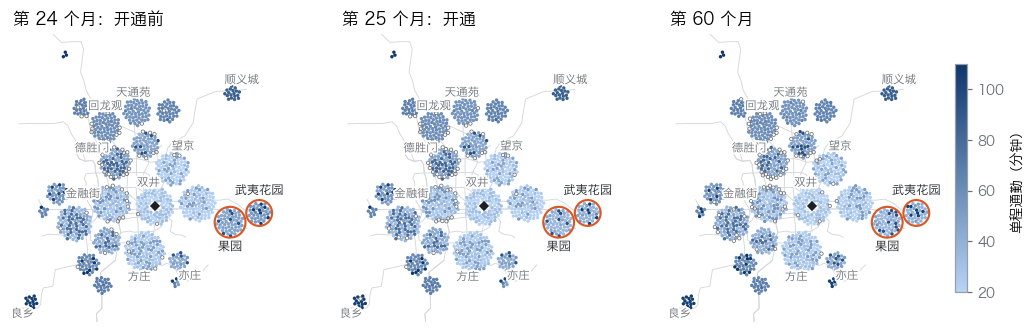

In [7]:
def room_state(arm, month):
    n = len(DATA["replay_rooms"])
    who, minutes = np.full(n, -1), np.zeros(n)
    for row in sorted(DATA["replay"], key=lambda r: r["month"]):
        if row["arm"] == arm and row["month"] <= month:
            for i, tenant, _, _, mins in row["rooms"]:
                who[i], minutes[i] = tenant, mins
    return who, minutes

cmap = LinearSegmentedColormap.from_list("commute", ["#b7d3f6", "#0d366b"])
halo = [patheffects.withStroke(linewidth=2.5, foreground="white")]
xs = np.array([r["x"] for r in DATA["replay_rooms"]])
ys = np.array([r["y"] for r in DATA["replay_rooms"]])
fig, axes = plt.subplots(1, 3, figsize=(13, 4.9))
for ax, month, title in zip(axes, [OPENS - 1, OPENS, MONTHS], [f"第 {OPENS - 1} 个月：开通前", f"第 {OPENS} 个月：开通", f"第 {MONTHS} 个月"]):
    who, minutes = room_state("C", month)
    for line in DATA["metro"]:
        pts = np.array(line["points"])
        ax.plot(pts[:, 0], pts[:, 1], color="#d5d8dc", lw=0.6, zorder=1)
    occupied = who >= 0
    dots = ax.scatter(xs[occupied], ys[occupied], c=minutes[occupied], cmap=cmap, vmin=20, vmax=110, s=5, linewidths=0, zorder=3)
    ax.scatter(xs[~occupied], ys[~occupied], facecolors="none", edgecolors=GREY, s=5, linewidths=0.5, zorder=3)
    for z in DATA["zones"]:
        if z["treated"]:
            ax.add_patch(plt.Circle((z["x"], z["y"]), z["r"], fill=False, color=ORANGE, lw=1.4, zorder=4))
        if z["treated"]:
            below = z["name"] == "果园"  # the two treated zones sit side by side, so their names go on opposite sides
            ax.text(z["x"], z["y"] + (z["r"] + 34) * (1 if below else -1), z["name"], fontsize=8, ha="center", va="center", color=INK, zorder=5, path_effects=halo)
        elif z["major"]:
            ax.text(z["lx"], z["ly"], z["name"], fontsize=7.5, ha="center", va="center", color=GREY, zorder=5, path_effects=halo)
    size = DATA["map"][0]
    ax.plot([size["cbd_x"]], [size["cbd_y"]], "D", color=INK, ms=4, zorder=6)
    ax.set_xlim(0, size["width"]); ax.set_ylim(size["height"], 0); ax.set_aspect("equal"); ax.axis("off")
    ax.set_title(title, loc="left")
fig.colorbar(dots, ax=axes, shrink=0.55, pad=0.01, label="单程通勤（分钟）")
plt.show()

## 逐月结果：通勤马上变，租金慢慢变

四组各 100 局的平均，浅色带是 A、C 两组的 95% 区间。竖线是开通，右侧阴影是统计窗口。

- **通勤：** 开通当月少 9.5 分钟，之后没有继续下降。
- **租金：** 开通前就在涨，到统计窗口已涨 5.1 点（A 组），这部分和新线无关。
- **租金差：** 第 48 个月 1.00，第 60 个月 1.58，到最后还在扩大。统计窗口的平均值 1.32 没有反映这个趋势。
- **询盘：** 开通后 12 个月，有新线比没有新线只多 4.1%。冻结组不统计询盘，所以只画两组。
- **地铁占比：** 新线后有人改坐地铁；但 A 组没有新线，也从 69% 降到 55%，基线本身在漂移。
- **搬入：** 开通后累计搬入受益区 34.2 人，没有新线时 37.8 人。可能是因为住在里面的人更少搬走，空出的房更少。

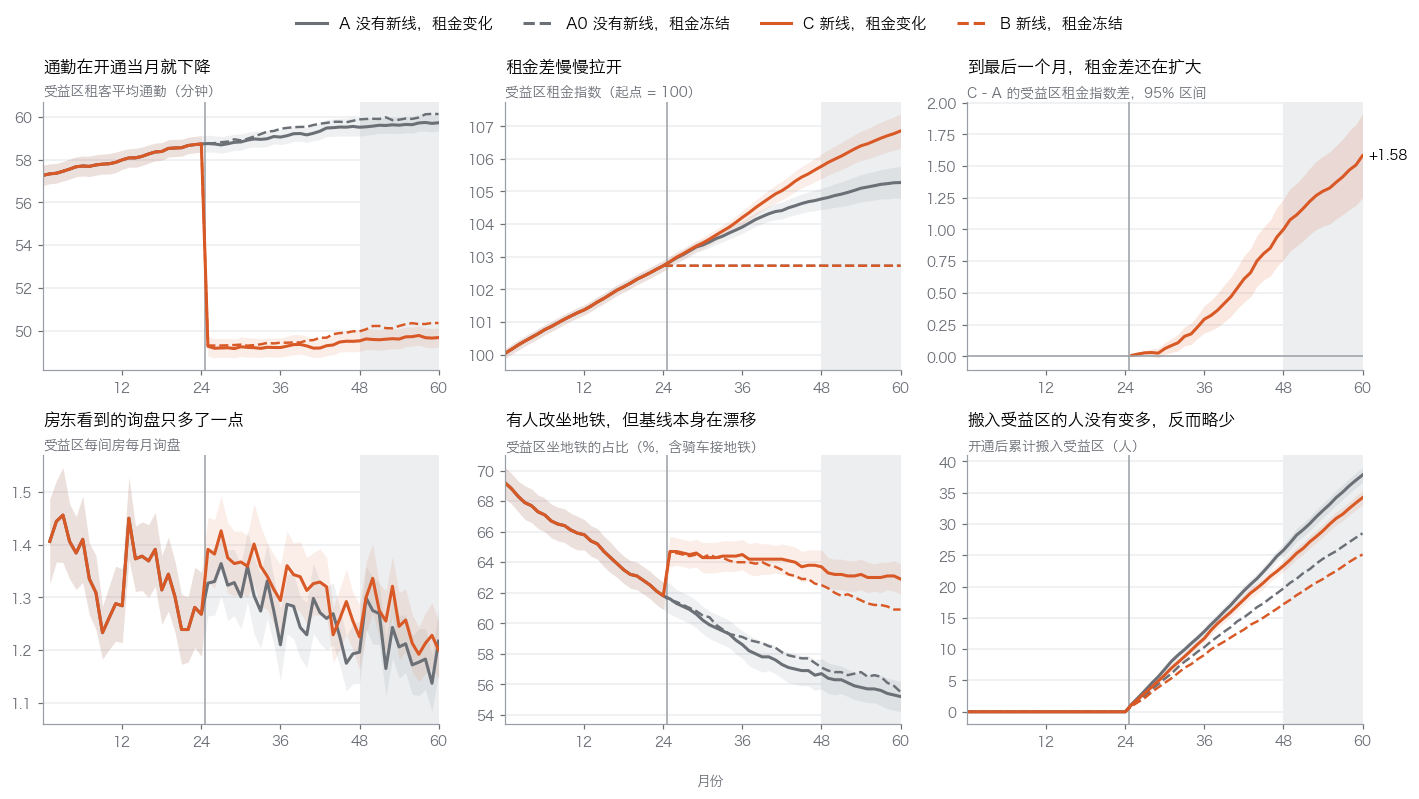

In [8]:
PANELS = [("watch_commute", "通勤在开通当月就下降", "受益区租客平均通勤（分钟）", ["A0", "B", "A", "C"]),
          ("watch_rent", "租金差慢慢拉开", "受益区租金指数（起点 = 100）", ["A0", "B", "A", "C"]),
          ("gap", "到最后一个月，租金差还在扩大", "C - A 的受益区租金指数差，95% 区间", None),
          ("inq_in", "房东看到的询盘只多了一点", "受益区每间房每月询盘", ["A", "C"]),
          ("mode_in_subway", "有人改坐地铁，但基线本身在漂移", "受益区坐地铁的占比（%，含骑车接地铁）", ["A0", "B", "A", "C"]),
          ("cum_in", "搬入受益区的人没有变多，反而略少", "开通后累计搬入受益区（人）", ["A0", "B", "A", "C"])]

fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, (metric, title, note, arms) in zip(axes.flat, PANELS):
    mark_time(ax)
    ax.set_title(title + "\n", loc="left")
    ax.text(0, 1.02, note, transform=ax.transAxes, fontsize=9, color=GREY)
    if metric == "gap":
        d = by_month[(by_month.metric == "watch_rent") & (by_month.effect == "total") & (by_month.month >= OPENS)].sort_values("month")
        ax.fill_between(d.month, d.value - d.half, d.value + d.half, color=ORANGE, alpha=0.14, lw=0)
        ax.plot(d.month, d.value, color=ORANGE, lw=2)
        ax.axhline(0, color="#9a9ea4", lw=1)
        ax.annotate(sign(d.value.iloc[-1], 2), (MONTHS, d.value.iloc[-1]), xytext=(4, 0), textcoords="offset points", fontsize=9, va="center", annotation_clip=False)
        continue
    for arm in arms:
        d = monthly[(monthly.metric == metric) & (monthly.arm == arm)].sort_values("month")
        if metric == "inq_in":
            d = d[d.month > 0]
        style = ARMS[arm]
        if arm in ("A", "C"):
            ax.fill_between(d.month, d["mean"] - d.half, d["mean"] + d.half, color=style["color"], alpha=0.1, lw=0)
        ax.plot(d.month, d["mean"], color=style["color"], ls=style["ls"], lw=2 if style["ls"] == "-" else 1.6, label=style["label"])
handles = [plt.Line2D([], [], color=ARMS[a]["color"], ls=ARMS[a]["ls"], lw=2, label=ARMS[a]["label"]) for a in ARMS]
fig.legend(handles=handles, loc="upper center", ncol=4, frameon=False, fontsize=10, bbox_to_anchor=(0.5, 1.03))
fig.supxlabel("月份", fontsize=9, color=GREY)
fig.tight_layout(rect=(0, 0, 1, 0.98))
plt.show()

## 效应分解

点是平均值，线段是 95% 区间，竖线是零。每行有自己的刻度，只看区间是否离开零；深色表示区间不含零。“累计”是开通后到第 60 个月的总数，其余是统计窗口的平均。

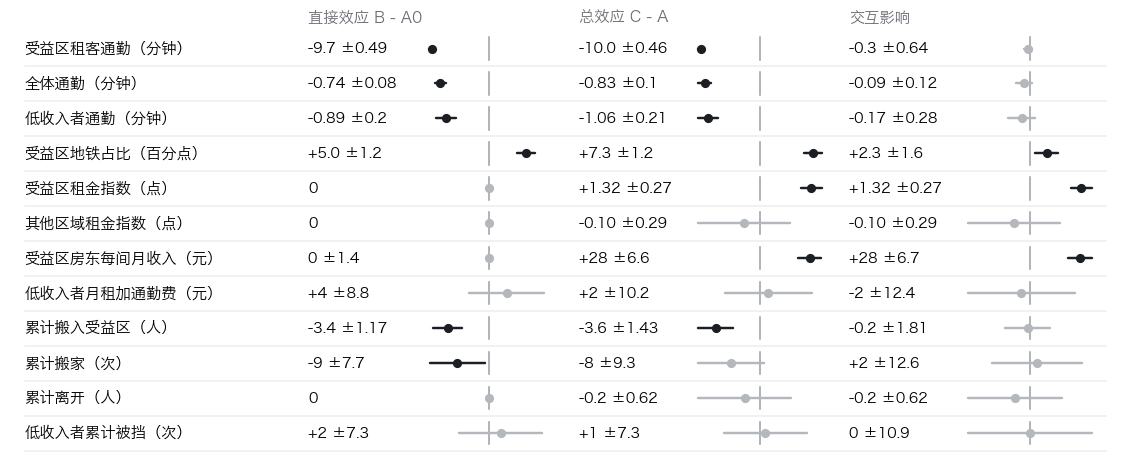

In [9]:
ROWS = [("watch_commute", "受益区租客通勤（分钟）"), ("commute", "全体通勤（分钟）"), ("low_commute", "低收入者通勤（分钟）"), ("mode_in_subway", "受益区地铁占比（百分点）"),
        ("watch_rent", "受益区租金指数（点）"), ("other_rent", "其他区域租金指数（点）"), ("rev_in", "受益区房东每间月收入（元）"), ("low_cash", "低收入者月租加通勤费（元）"),
        ("cum_in", "累计搬入受益区（人）"), ("cum_moves", "累计搬家（次）"), ("cum_left", "累计离开（人）"), ("cum_blocked", "低收入者累计被挡（次）")]
COLUMNS = [("direct", "直接效应 B - A0"), ("total", "总效应 C - A"), ("interaction", "交互影响")]

fig, ax = plt.subplots(figsize=(13, 5.2))
ax.set_xlim(-0.05, 4.05); ax.set_ylim(len(ROWS) - 0.4, -1); ax.axis("off")
for j, (_, head) in enumerate(COLUMNS):
    ax.text(1.05 + j, -0.75, head, fontsize=10, color=GREY)
for i, (metric, label) in enumerate(ROWS):
    ax.text(0, i, label, fontsize=10, va="center")
    ax.plot([0, 4], [i + 0.5, i + 0.5], color="#eceef0", lw=1)
    rows = effects[effects.metric == metric].set_index("effect")
    scale = (rows.value.abs() + rows.half).max() * 1.05 or 1
    for j, (effect, _) in enumerate(COLUMNS):
        r = rows.loc[effect]
        digits = int(r.digits)
        ax.text(1.05 + j, i, f"{sign(r.value, digits)}" + (f" ±{r.half:g}" if r.half > 0 else ""), fontsize=9.5, va="center")
        centre, width = 1.72 + j, 0.24
        ax.plot([centre, centre], [i - 0.32, i + 0.32], color="#9a9ea4", lw=1)
        clear = abs(r.value) > r.half and r.half > 0
        whisker(ax, centre + r.value / scale * width, centre + (r.value - r.half) / scale * width, centre + (r.value + r.half) / scale * width, i, INK if clear else MUTED)
plt.show()

## 好处和代价分给了谁

受益区里，低收入者省的时间最多（-11.3 分钟）。房东每间房的月收入小幅增加（+28 元），其他区域的人和房东几乎不受影响。这是统计窗口内各组住户的平均，住户在换，不是跟踪同一批人。

In [10]:
def pair(v, h, d):
    return "" if pd.isna(v) else f"{sign(v, d)} ±{h:.{d}f}"

def tenant_table(where):
    rows = ledger[(ledger["where"] == where) & ledger.n.notna()]
    return pd.DataFrame({"谁": rows.who, "人数（C 组）": rows.n.astype(int), "通勤（B − A0，分钟）": [pair(a, b, 1) for a, b in zip(rows.commute, rows.commute_h)],
                         "月租（C − A，元）": [pair(a, b, 0) for a, b in zip(rows.rent, rows.rent_h)], "通勤费（B − A0，元）": [pair(a, b, 0) for a, b in zip(rows.fare, rows.fare_h)]}).set_index("谁")

print("受益区的租客"); display(tenant_table("受益区"))
print("其他区域的租客"); display(tenant_table("其他区域"))
owners = ledger[ledger.n.isna()]
print("房东"); display(pd.DataFrame({"区域": owners["where"], "每间房月收入（C − A，元）": [pair(a, b, 0) for a, b in zip(owners.rent, owners.rent_h)]}).set_index("区域"))

受益区的租客


,人数（C 组）,通勤（B − A0，分钟）,月租（C − A，元）,通勤费（B − A0，元）
谁,,,,
较低收入租客,30,-11.3 ±0.6,+31 ±17,-7 ±20
中等收入租客,39,-9.5 ±0.8,+75 ±41,-17 ±29
较高收入租客,21,-7.6 ±1.1,+29 ±30,-51 ±54


其他区域的租客


,人数（C 组）,通勤（B − A0，分钟）,月租（C − A，元）,通勤费（B − A0，元）
谁,,,,
较低收入租客,290,+0.2 ±0.2,0 ±6,+3 ±7
中等收入租客,416,-0.2 ±0.2,+2 ±13,+6 ±8
较高收入租客,324,+0.2 ±0.2,+7 ±14,-8 ±11


房东


,每间房月收入（C − A，元）
区域,
受益区,+28 ±7
其他区域,-1 ±5


## 分区结果：只有两个受益区明显变化

周边区域没有明显的外溢。空置率很低也不是受益区独有的：18 个区域低于 5%，高空置集中在 4 个区域，最高 25.7%；扣掉这些区域，其他区域约 2.7%。所以受益区 0.3% 与其他区域 7.3% 的对比，主要反映少数区域空置很高。

按地铁门到门时间从近到远排列。空置率来自 A 组统计窗口；租金差是 C − A，通勤差是 B − A0。

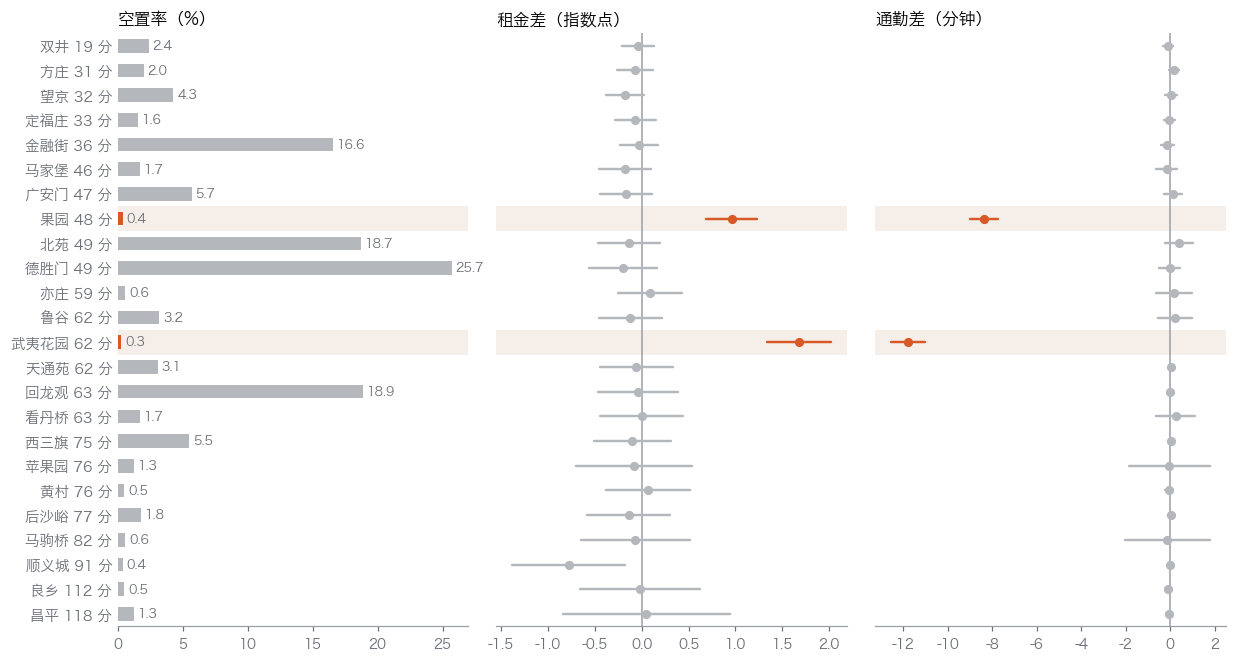

In [11]:
z = zones.sort_values("subway").reset_index(drop=True)
y = np.arange(len(z))
fig, axes = plt.subplots(1, 3, figsize=(13, 7), sharey=True, gridspec_kw={"wspace": 0.08})
colors = [ORANGE if t else MUTED for t in z.treated]
for ax in axes:
    for i in y[z.treated]:
        ax.axhspan(i - 0.5, i + 0.5, color="#f6efe9", lw=0, zorder=0)
    ax.spines["left"].set_visible(False)
    ax.tick_params(axis="y", length=0)
axes[0].barh(y, z.vac, color=colors, height=0.55)
for i, v in zip(y, z.vac):
    axes[0].text(v + 0.3, i, f"{v:.1f}", va="center", fontsize=8.5, color=GREY)
axes[0].set_title("空置率（%）")
axes[0].set_yticks(y, [f"{n} {m} 分" for n, m in zip(z.name, z.subway)], fontsize=9.5)
axes[0].set_ylim(len(z) - 0.5, -0.5)
for ax, value, half, title in ((axes[1], "rent", "rent_h", "租金差（指数点）"), (axes[2], "commute", "commute_h", "通勤差（分钟）")):
    ax.axvline(0, color="#9a9ea4", lw=1)
    for i, r in z.iterrows():
        whisker(ax, r[value], r[value] - r[half], r[value] + r[half], i, ORANGE if r.treated else MUTED)
    ax.set_title(title)
plt.show()

## 和真实数据、其他假设对照

**左图：** 新线的租金差。真实线路的点估计有正有负，多数区间包含零；规则版的估计落在 14、16 号线的区间内。两边窗口和口径不同，只比量级，真实值也只是描述性比较。

**右图：** 改假设后，受益区的租金差（C − A，早先的假设检验，局数较少）。

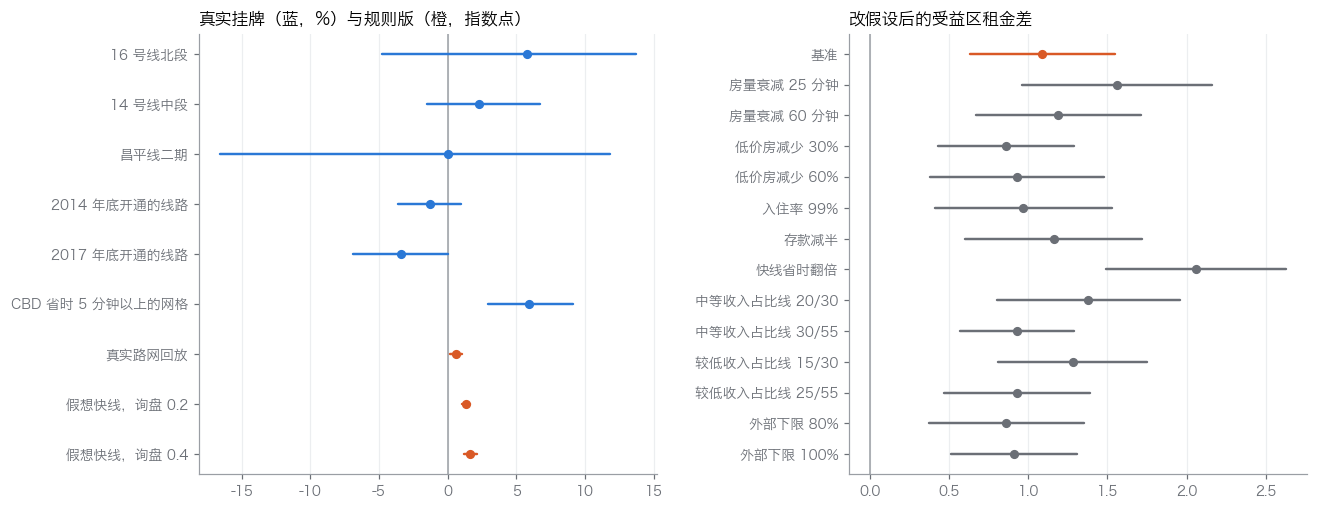

In [12]:
fig, (left, right) = plt.subplots(1, 2, figsize=(13, 5.2), gridspec_kw={"wspace": 0.42})
rows = real_vs_rule.iloc[::-1].reset_index(drop=True)
for i, r in rows.iterrows():
    rule = r.group.startswith("规则")
    whisker(left, r.value, r.lo, r.hi, i, ORANGE if rule else BLUE)
left.axvline(0, color="#9a9ea4", lw=1)
left.set_yticks(rows.index, rows.label)
left.set_title("真实挂牌（蓝，%）与规则版（橙，指数点）")
left.grid(axis="x", color="#eceef0"); left.set_axisbelow(True)
rows = assumptions.iloc[::-1].reset_index(drop=True)
for i, r in rows.iterrows():
    whisker(right, r.premium, r.premium - r.premium_h, r.premium + r.premium_h, i, ORANGE if r.variant == "base" else GREY)
right.axvline(0, color="#9a9ea4", lw=1)
right.set_yticks(rows.index, rows.label)
right.set_title("改假设后的受益区租金差")
right.grid(axis="x", color="#eceef0"); right.set_axisbelow(True)
plt.show()

**低价房减少的影响比新线大得多。** 低价房和便宜单间一起减少，来自同一组假设检验。

In [13]:
low = assumptions[assumptions.variant.isin(["base", "low-cost rooms -30%", "low-cost rooms -60%"])]
display(pd.DataFrame({"低价房": ["现状", "减少 30%", "减少 60%"], "入住户数": low.seated.values, "低收入者房租超 30%（%）": low.low_over30.values, "在住者离开（人）": low.left.values, "低收入新来者被挡（次）": low.blocked_low.values}).set_index("低价房"))

,入住户数,低收入者房租超 30%（%）,在住者离开（人）,低收入新来者被挡（次）
低价房,,,,
现状,1134,20,9.6,228.7
减少 30%,1118,26,13.7,249.9
减少 60%,1082,41,18.3,271.3


**房东的定价规则改变租金差。** 交互影响（指数点）。询盘强度是假设，没有按真实溢价调参。

In [14]:
display(pd.DataFrame({"房东规则": rules.label, "假想快线": [f"{a:+.2f} ±{b:.2f}" for a, b in zip(rules.express, rules.express_h)], "真实路网回放": [f"{a:+.2f} ±{b:.2f}" for a, b in zip(rules.replay, rules.replay_h)]}).set_index("房东规则"))

,假想快线,真实路网回放
房东规则,,
只看空置率,+0.14 ±0.11,+0.29 ±0.21
加询盘，强度 0.2（基准）,+1.32 ±0.27,+0.61 ±0.45
加询盘，强度 0.4,+1.63 ±0.48,+0.31 ±0.57


**基线和现实比较。** A 组，统计窗口。局数比早先的基线多，数字略有差别。上班方式已用北京调查校准，这里的比较不算完全独立。

In [15]:
display(baseline.rename(columns={"metric": "指标", "model": "模型", "real": "现实"}).set_index("指标"))

,模型,现实
指标,,
平均通勤（分钟）,48.4,48（2021，通勤监测报告）
60 分钟以上占比（%）,24.0,28–30（通勤监测报告）
房租占收入（%）,22.0,24.0–26.3（贝壳与清华，北京）
低收入者房租超过 30%（%）,20.0,近 3 成（贝壳与清华，全国）
